In [77]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import re
import string
import joblib
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from annotated_types import Len
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, accuracy_score, f1_score


In [2]:
# load the sms dataset
df = pd.read_csv("SMSSpamCollection", 
    sep="\t", 
    header=None, 
    names=["label", "message"]
    )
    

In [3]:
#display the first 5 rows of the dataset

df.head()

,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
#check the shape of the dataset

df.shape

(5572, 2)

In [5]:
#check the dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB


In [6]:
#check for missing values 

df.isnull()

,label,message
0,False,False
1,False,False
2,False,False
3,False,False
4,False,False
...,...,...
5567,False,False
5568,False,False
5569,False,False
5570,False,False


In [7]:
#count the missing values in each column

df.isnull().sum()

label      0
message    0
dtype: int64

In [8]:
#count the number of spam and ham messages in the dataset

df["label"].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [9]:
#To calculate the percentage of spam and ham messages in the dataset

df["label"].value_counts(normalize=True)* 100

label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64

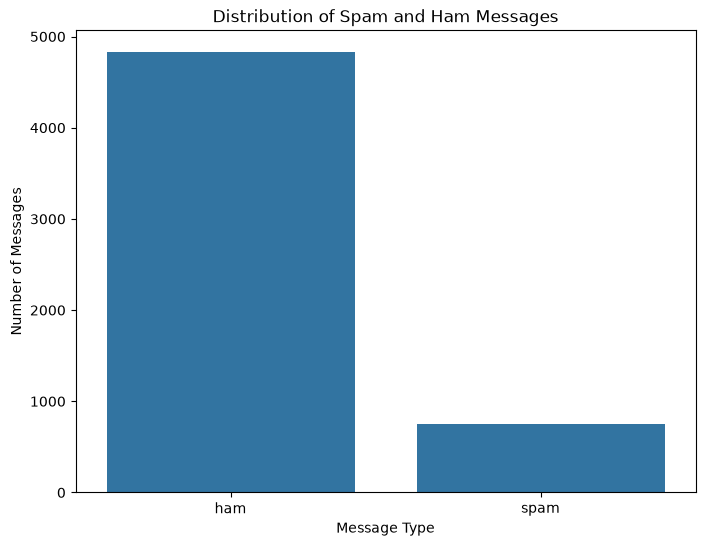

In [10]:
#visualize the dataset

plt.figure(figsize=(8,6))
sns.countplot(x="label", data=df)

plt.title("Distribution of Spam and Ham Messages")
plt.xlabel("Message Type")
plt.ylabel("Number of Messages")

plt.show()

In [11]:
# Preprocess the text data
#convert all text to lowercase 

df["message"] = df["message"].str.lower()


In [12]:
df["message"].head()

0    go until jurong point, crazy.. available only ...
1                        ok lar... joking wif u oni...
2    free entry in 2 a wkly comp to win fa cup fina...
3    u dun say so early hor... u c already then say...
4    nah i don't think he goes to usf, he lives aro...
Name: message, dtype: str

In [13]:
#Remove punctuation and special characters from the text data

def remove_punctuation(text):
    return 
    text.translate(str.maketrans('', '', string.punctuation))


In [14]:
#testing the function on a sample text
sample_text = "Hello! How are you doing today?" 

cleaned = remove_punctuation(sample_text)
print(cleaned)  # Output: Hello How are you doing today

None


In [15]:
#apply punctuation removal function to the entire dataset
df["message"] = df["message"].apply(remove_punctuation)

In [16]:
df["message"].head()

0    None
1    None
2    None
3    None
4    None
Name: message, dtype: object

In [17]:
#remove unnecessary spaces
df["message"] = df["message"].str.strip()

In [18]:
#create a complete text cleaning function
def clean_text(text):
    
    #ensure that the text is a string
    text = str(text)

    # Convert to lowercase
    text = text.lower()
    
    # Remove punctuation
    text = re.sub(r"[^\w\s]", " ", text)
    
    # Remove unnecessary spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

In [19]:
print(type(clean_text))  
print(df["message"].isnull().sum())
print(df["message"].head())  

<class 'function'>
5572
0    None
1    None
2    None
3    None
4    None
Name: message, dtype: object


In [20]:
#apply the complete  cleaning function to the entire dataset
df["clean_message"] = df["message"].apply(clean_text)

In [21]:
#compare the original message and the cleaned message
for i in range(5):
    print("original message:")
    print(df["message"].iloc[i])

    print("cleaned message:")
    print(df["clean_message"].iloc[i])

    print("-" * 50)

    

original message:
None
cleaned message:
none
--------------------------------------------------
original message:
None
cleaned message:
none
--------------------------------------------------
original message:
None
cleaned message:
none
--------------------------------------------------
original message:
None
cleaned message:
none
--------------------------------------------------
original message:
None
cleaned message:
none
--------------------------------------------------


In [22]:
#check the cleaned dataset
df["clean_message"].head()

0    none
1    none
2    none
3    none
4    none
Name: clean_message, dtype: str

In [23]:
df[["message", "clean_message"]].isnull().sum()

message          5572
clean_message       0
dtype: int64

In [24]:
#Analyze the number of spam and ham messages in the cleaned dataset

df["label"].value_counts()

label
ham     4825
spam     747
Name: count, dtype: int64

In [25]:
#calculate the percentage of spam and ham messages in the cleaned dataset

df["label"].value_counts(normalize=True)* 100   

label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64

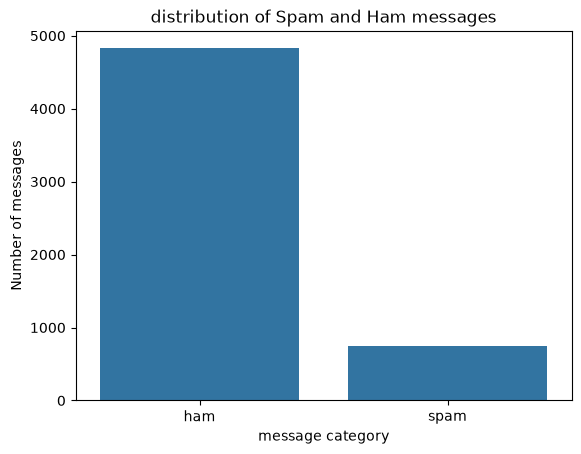

In [26]:
#visualize spam and ham messages
plt.Figure(figsize=(8, 5))

sns.countplot(data= df, x="label")
plt.title("distribution of Spam and Ham messages")
plt.xlabel("message category")
plt.ylabel("Number of messages")

plt.show()


In [27]:
#Analyze the length of the messages in the dataset
df["message_length"] = df["clean_message"].apply(len)

In [28]:
#Display result
df[["clean_message", "message_length"]].head(10)

,clean_message,message_length
0,none,4
1,none,4
2,none,4
3,none,4
4,none,4
5,none,4
6,none,4
7,none,4
8,none,4
9,none,4


In [29]:
#compare the average length of spam and ham messages
df.groupby("label")["message_length"].mean()

label
ham     4.0
spam    4.0
Name: message_length, dtype: float64

In [30]:
print(df.columns.tolist())

['label', 'message', 'clean_message', 'message_length']


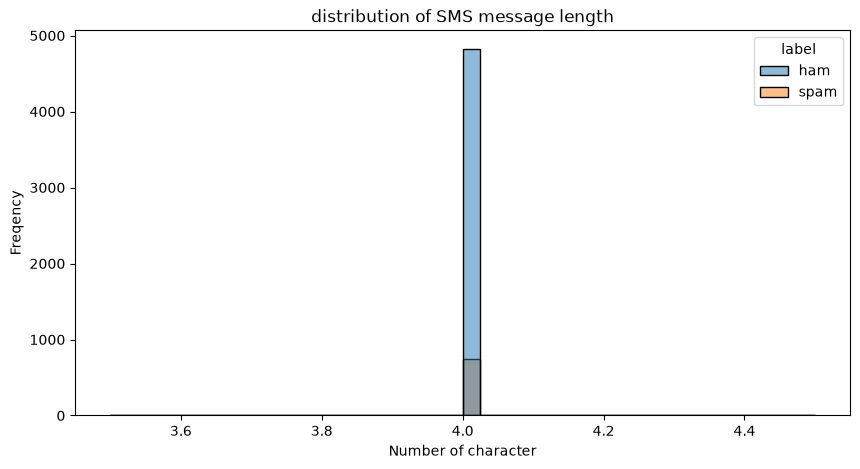

In [31]:
#visualize message length
plt.figure(figsize=(10, 5))

sns.histplot(
    data = df,
    x ="message_length",
    hue = "label",
    bins = 40,
    
)
plt.title("distribution of SMS message length")
plt.xlabel("Number of character")
plt.ylabel("Freqency")

plt.show()

In [32]:
#Identify the most common words in spam spammers
spam_messages = df[df["label"] == "spam"]


In [33]:
#combine all the spam messages
spam_text = " ".join(spam_messages["clean_message"])

In [34]:
#extract individual words
spam_words = spam_text.split()

In [35]:
#count the words
spam_word_counts = Counter(spam_words)

In [36]:
spam_word_counts.most_common(15)

[('none', 747)]

In [37]:
#identify the most common words in legitiment messages

ham_messages = df[df["label"] == "spam"]

ham_text= " ".join(ham_messages["clean_message"])
ham_words = ham_text.split()
ham_word_counts = Counter(ham_words)
ham_word_counts.most_common(15)

[('none', 747)]

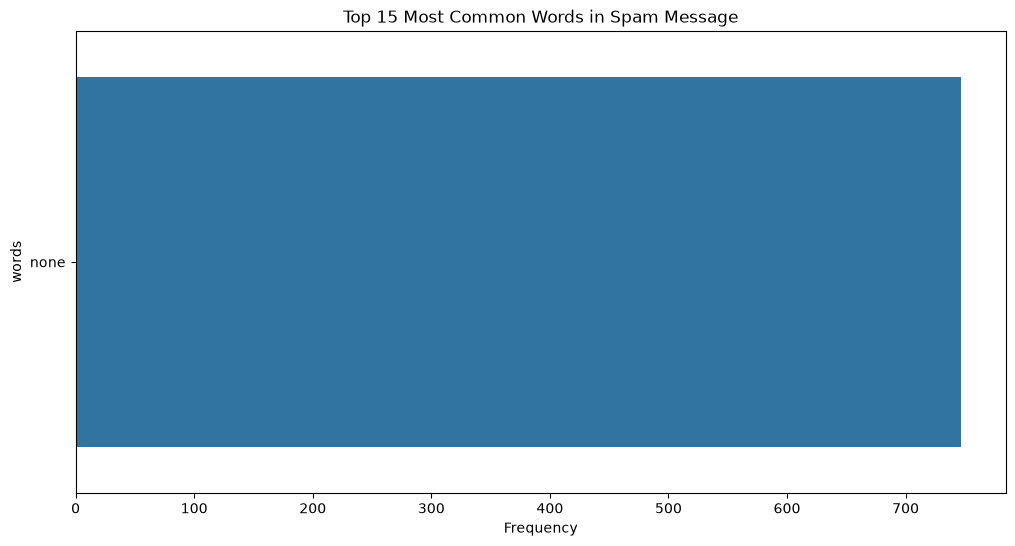

In [38]:
#creat a word frequency char for spam
spam_top_words = spam_word_counts.most_common(15)

words = [word for word, count in spam_top_words]

counts = [count for word, count in spam_top_words]

plt.figure(figsize=(12, 6))
sns.barplot(x = counts, y = words)

plt.title("Top 15 Most Common Words in Spam Message")
plt.xlabel("Frequency")
plt.ylabel("words")

plt.show()

In [39]:
#prepare the independent and dependent variables.
# for this project X represent the input feature (SMS messages)
# and y represent the target variable (Spam or legitimate classification)

#independent variable (SMS messages)
X = df["clean_message"]

#Dependent variable (target lables)
y = df["label"].map({
    "ham": 0,
    "spam": 1
})

In [40]:
#check the Result
print(X.head())
print(y.head())

0    none
1    none
2    none
3    none
4    none
Name: clean_message, dtype: str
0    0
1    0
2    1
3    0
4    0
Name: label, dtype: int64


In [41]:
print(y.isnull().sum())

0


In [42]:
#split dataset into training and testing set
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state= 42,
    stratify= y
)

In [43]:
#check sizes

print("Traing messages: ", Len(X_train))
print("Testing messages: ", len(X_test))

Traing messages:  Len(min_length=184     none
2171    none
5422    none
4113    none
4588    none
        ... 
1932    none
5316    none
2309    none
1904    none
762     none
Name: clean_message, Length: 4457, dtype: str, max_length=None)
Testing messages:  1115


In [44]:
#Apply TF-IDF Vectorization
#create the TF-IDF vectorizer

tfidf = TfidfVectorizer()

#learn vocabulary and transform training messages

X_train_tfidf = tfidf.fit_transform(X_train)

#Transform testing messages using the same vocabulary
X_test_tfidf = tfidf.transform(X_test)

In [45]:
#check the numerical output

print("Training data shape: ", X_train_tfidf.shape)

print("Testing data shape: ", X_test_tfidf.shape)

Training data shape:  (4457, 1)
Testing data shape:  (1115, 1)


In [46]:
#Examine the vocabulary
print(tfidf.get_feature_names_out()[:30])

['none']


In [47]:
#also examine numerical representation

print(X_train_tfidf[0].toarray())

[[1.]]


In [48]:
#model training
#Train the first model: Naive Bayes

#create the Naive Bayes model
nB_model = MultinomialNB()

#Train the model
nB_model.fit(X_train_tfidf, y_train)

#make prediction
nB_predictions = nB_model.predict(X_test_tfidf)

print("Naive Bayes model trained successfully")


Naive Bayes model trained successfully


In [49]:
#Evaluate the Naive Bayes model

#calculate model accurency
nB_accuracy = accuracy_score(y_test, nB_predictions)

print("Naive Bayes Accurancy: ", nB_accuracy)

Naive Bayes Accurancy:  0.8663677130044843


In [50]:
#calculate precision and recall for spam

#calculate precision for spam
nB_precision = precision_score(
    y_test,
    nB_predictions,
    pos_label= 1
)

#calculate recall spam
nB_recall = recall_score(
    y_test,
    nB_predictions,
    pos_label= 1
)

print("Spam Precision: ", nB_precision)

print("Spam recall: ", nB_recall)


Spam Precision:  0.0
Spam recall:  0.0


c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [51]:
#Generate the classification report
print(classification_report(
    y_test,
    nB_predictions,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.87      1.00      0.93       966
        Spam       0.00      0.00      0.00       149

    accuracy                           0.87      1115
   macro avg       0.43      0.50      0.46      1115
weighted avg       0.75      0.87      0.80      1115



c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

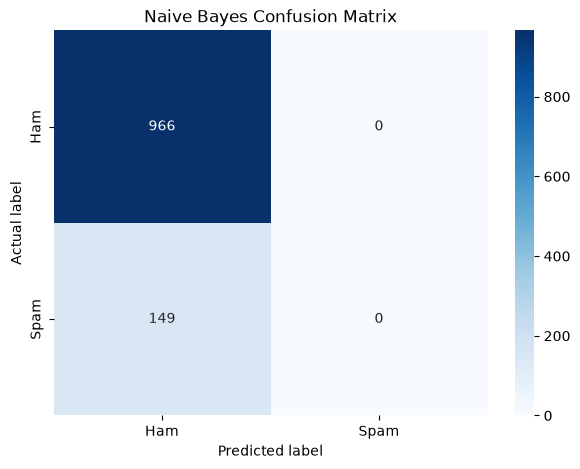

In [52]:
#Create the Naive Bayes confusion matrix

#generate confusion matrix
nB_cm = confusion_matrix(y_test, nB_predictions)

#plot confusion matrix
plt.figure(figsize= (7, 5))

sns.heatmap(
    nB_cm,
    annot= True,
    fmt= "d",
    cmap= "Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")

plt.show()

In [53]:
#Train the second model

#Create logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

#Train the model
lr_model.fit(X_train_tfidf, y_train)

#make prediction
lr_predictions = lr_model.predict(X_train_tfidf)

print("Logistic Regression trained successfully")


Logistic Regression trained successfully


In [54]:
#Evaluate Logistic Regression

lr_predictions = lr_model.predict(X_test_tfidf)

lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_precision = precision_score(
    y_test,
    lr_predictions,
    pos_label= 1
)
lr_recall =recall_score(
    y_test,
    lr_predictions,
    pos_label= 1
)

print("Logistic Regression Accuracy: ", lr_accuracy)

print("Spam Precision: ", lr_precision)

print("Spam Recall: ", lr_recall)

Logistic Regression Accuracy:  0.8663677130044843
Spam Precision:  0.0
Spam Recall:  0.0


c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [55]:
#Generate its classification report

lr_predictions = lr_model.predict(X_test_tfidf)
print(classification_report(
    y_test,
    lr_predictions,
    target_names=["Ham", "Spam"]
))


              precision    recall  f1-score   support

         Ham       0.87      1.00      0.93       966
        Spam       0.00      0.00      0.00       149

    accuracy                           0.87      1115
   macro avg       0.43      0.50      0.46      1115
weighted avg       0.75      0.87      0.80      1115



c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

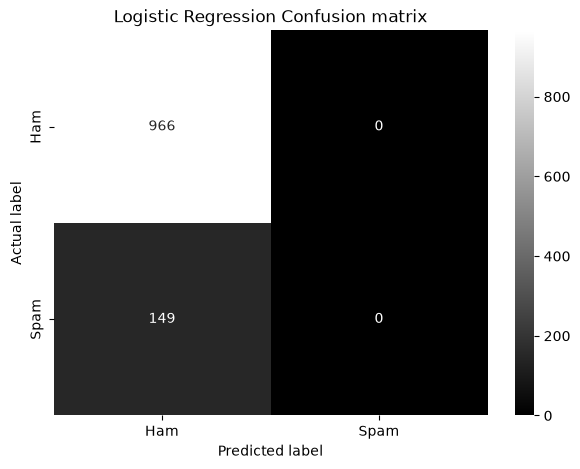

In [56]:
#Create Logistic Regression confusion matrix

lr_cm = confusion_matrix(y_test, lr_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    lr_cm,
    annot = True,
    fmt= "d",
    cmap= "grey",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Logistic Regression Confusion matrix")

plt.xlabel("Predicted label")

plt.ylabel("Actual label")
plt.show()


In [57]:
#compare both Machine Learning models

#Create a comprison table
model_comparison = pd.DataFrame({
    "Model": ["Naive Bayes", "Logistic Regression"],
    
    "Accuracy": [nB_accuracy, lr_accuracy],

    "Spam Precision": [nB_precision, lr_precision],

    "Spam Recall": [nB_recall, lr_recall]
})

model_comparison


,Model,Accuracy,Spam Precision,Spam Recall
0,Naive Bayes,0.866368,0.0,0.0
1,Logistic Regression,0.866368,0.0,0.0


In [58]:
#Model testing and Improvement

#create a new SMS messages
new_messages = [
    "congratulation! you have won a free ticket. callnow",
    "Hello, how are you doing today?",
    "urgent! your account has been compromised.",
    "please call me back when you get a chance.",
    "you have been selected for a special offer."
]

In [59]:
#convert new messages using TF-IDF vectorization

new_messages_tfidf = tfidf.transform(new_messages)

In [60]:
#make predictions ising Naive Bayes model
nB_new_predictions = nB_model.predict(new_messages_tfidf)
print("Naive Bayes Predictions: ", nB_new_predictions)

Naive Bayes Predictions:  [0 0 0 0 0]


In [61]:
#make prediction using Logistic Regression model
lr_new_predictions = lr_model.predict(new_messages_tfidf)
print("Logistic Regression Predictions: ", lr_new_predictions)

Logistic Regression Predictions:  [0 0 0 0 0]


In [62]:
#calculate prediction confidence score
lr_probalities = lr_model.predict_proba(new_messages_tfidf)

#get the probabilities of the predicted class
lr_confidence = lr_probalities.max(axis=1)

print( lr_confidence)

[0.86582012 0.86582012 0.86582012 0.86582012 0.86582012]


In [63]:
#create prediction result
results = pd.DataFrame({
    "Message": new_messages,
    "Naive Bayes Prediction": [
        "Spam" if p == 1 else "Not Spam"
        for p in nB_new_predictions
    ],
    "Logistic Regression Prediction": [
        "Spam" if p == 1 else "Not Spam"
        for p in lr_new_predictions
    ],
    "LR confidence":[
        f"{p* 100:.2f}%" 
        for p in lr_confidence

    ]
})
results

,Message,Naive Bayes Prediction,Logistic Regression Prediction,LR confidence
0,congratulation! you have won a free ticket. ca...,Not Spam,Not Spam,86.58%
1,"Hello, how are you doing today?",Not Spam,Not Spam,86.58%
2,urgent! your account has been compromised.,Not Spam,Not Spam,86.58%
3,please call me back when you get a chance.,Not Spam,Not Spam,86.58%
4,you have been selected for a special offer.,Not Spam,Not Spam,86.58%


In [64]:
#compare actual and predicted labels 
error_analysis = pd.DataFrame({
    "Message": X_test.values,
    "Actual" : y_test.values,
    "predicted": lr_predictions
})

#Select incorrectly classified messages
errors = error_analysis[
    error_analysis["Actual"] != error_analysis["predicted"]
]
errors.head(10)

,Message,Actual,predicted
3,none,1,0
23,none,1,0
35,none,1,0
40,none,1,0
44,none,1,0
65,none,1,0
67,none,1,0
83,none,1,0
89,none,1,0
94,none,1,0


In [65]:
#check the number of mistakes
print("Total incorrect predictions: ", len(errors))

Total incorrect predictions:  149


In [66]:
#Improve the model
lr_balanced = LogisticRegression(
    max_iter=1000, 
    class_weight="balanced"
)

#Train the model
lr_balanced.fit(X_train_tfidf, y_train)

#make prediction
lr_balanced_predictions = lr_balanced.predict(X_test_tfidf) 

print("Balanced Logistic Regression trained successfully")

Balanced Logistic Regression trained successfully


In [67]:
#evaluate the balanced Logistic Regression model
print(classification_report(
    y_test,
    lr_balanced_predictions,
    target_names=["Ham", "Spam"]
))

              precision    recall  f1-score   support

         Ham       0.87      1.00      0.93       966
        Spam       0.00      0.00      0.00       149

    accuracy                           0.87      1115
   macro avg       0.43      0.50      0.46      1115
weighted avg       0.75      0.87      0.80      1115



c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\user\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

In [69]:
#calculate spam F1 score
nB_f1 = f1_score(
    y_test,
    nB_predictions,
    pos_label= 1
)
lr_f1 = f1_score(
    y_test,
    lr_predictions,
    pos_label= 1
)
balanced_f1 = f1_score(
    y_test,
    lr_balanced_predictions,
    pos_label= 1
)
#compare the  models
comparison = pd.DataFrame({
    "Model": ["Naive Bayes", 
              "Logistic Regression",
              "Balanced Logistic Regression"
        ],
        "Spam f1 Score": [nB_f1,
                           lr_f1, 
                           balanced_f1
        ]
})
comparison

,Model,Spam f1 Score
0,Naive Bayes,0.0
1,Logistic Regression,0.0
2,Balanced Logistic Regression,0.0


In [76]:
#Select the best perfoerming model
models = {
    "Naive Bayes": nB_model,
    "Logistic Regression": lr_model,
    "Balanced Logistic Regression": balanced_f1
}
f1_score = {
    "Naive Bayes": nB_f1,
    "Logistic Regression": lr_f1,
    "Balanced Logistic Regression": balanced_f1
}

best_model_name = max(f1_score, key=f1_score.get)
best_model = models[best_model_name]

print("Selected model: ", best_model_name)

print("Spam f1 score:" , f1_score[best_model_name])

Selected model:  Naive Bayes
Spam f1 score: 0.0


In [79]:
#save selected model and TF-IDF vectorizer
joblib.dump(best_model, "sms_spam_detector_model.pkl")

#save the TF-IDF vectorizer
joblib.dump(tfidf, "tfidf_vectorizer.pkl")

print("Model and TF-IDF vectorizer saved successfully.")


Model and TF-IDF vectorizer saved successfully.
